# Data Preparation

For the analysis, we will use a spatial grid to break down the distribution of the ecosystems into different sections or regions. 

For convenience, we will use the Area of Occupancy grid or AOO that is recommended for ecosystem risk assessments [@IUCN_2025]. 

## Area of Occupancy grid

We will create the AOO grid using functions from R package [`redlistr`](https://github.com/red-list-ecosystem/redlistr).

In [16]:
#| warnings: false
library(redlistr)
library(sf)
library(dplyr)


We use the `here::i_am` function to establish our project root folder and use relative paths to locate input data files.

In [3]:
here::i_am("ecosystem/spatial-metrics.ipynb")

here() starts at /Users/z3529065/proyectos/EIW/SA-fleurieu-landcover



We read the vector data generated in the previous step and project the data.

In [7]:
fleurieu_imap <- st_read(here::here("gisdata/TEC/Swamps-Fleurieu-IM.gpkg")) |>
    st_transform( "EPSG:7853") 

Reading layer `ECnes_public' from data source 
  `/Users/z3529065/proyectos/EIW/SA-fleurieu-landcover/gisdata/TEC/Swamps-Fleurieu-IM.gpkg' 
  using driver `GPKG'
Simple feature collection with 240 features and 12 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: 138.164 ymin: -35.649 xmax: 139.001 ymax: -35.274
Geodetic CRS:  GDA94


We run the `getAOO` function to extract an optimal grid covering the areas of the indicative distribution map.

In [11]:
fleurieu_AOO <- getAOO(fleurieu_imap)


Initialising grids

Assembling initial grids

Running jitter on units with 100 or fewer cells, n = 35

jittering  



We do a quick plot to check the distribution of the target ecosystem and the AOO grid on top of it. We visually check that there is no misalignment or excluded areas.

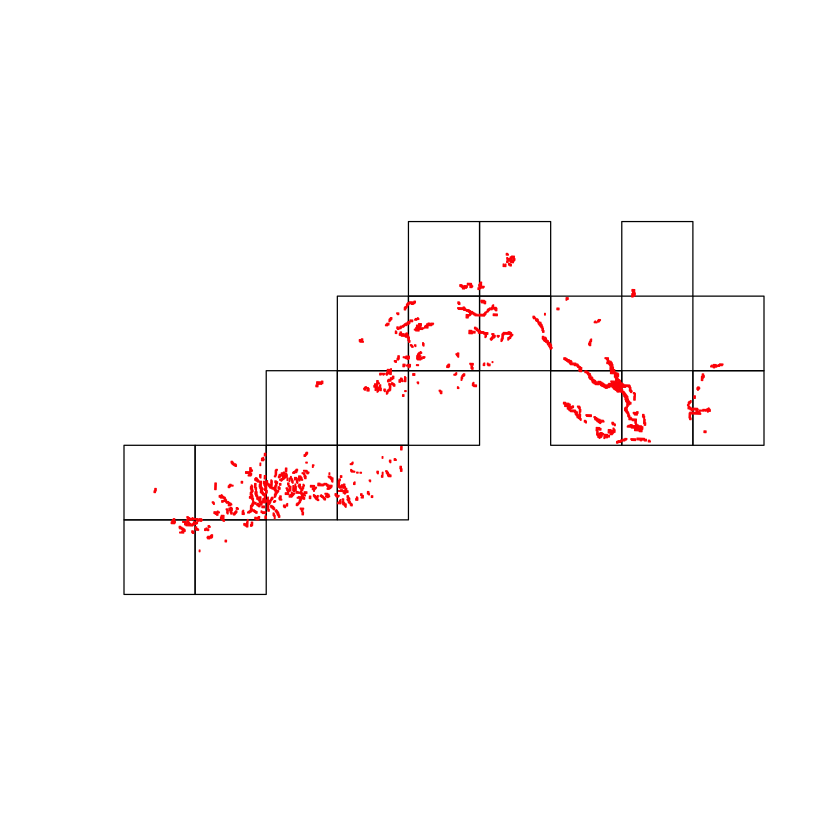

In [14]:
plot(st_geometry(fleurieu_AOO@grid))
plot(st_geometry(fleurieu_imap), add=TRUE, col="red", border="red")

We are satisfied with this grid, and we export it in Geopackage format (GPKG).

In [ ]:
write_sf(
  fleurieu_AOO@grid,
  here::here("gisdata/TEC/Swamps-Fleurieu-IM_AOO.gpkg")
)